In [1]:
import sys
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
cwd = Path.cwd()
project_root = cwd.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print("Done!")

Done!


In [3]:
ss_df = pd.read_csv(project_root / 'data' / 'enem_scores.csv')
ss_df.head()

,year,school_id,number_of_students,avg_score
0,2007,11000058,144,69.03
1,2006,11000058,184,57.82
2,2005,11000058,220,64.83
3,2006,11000198,51,51.69
4,2005,11000198,47,50.16


In [4]:
ss_df.sort_values(by='avg_score', ascending=False).head(10)

,year,school_id,number_of_students,avg_score
16670,2007,33062633,68,82.97
16796,2007,33065403,172,82.04
16668,2005,33062633,59,81.89
16794,2005,33065403,177,81.66
10043,2007,29342880,43,80.32
18121,2007,33152314,14,79.82
16781,2007,33065250,80,79.67
3026,2007,22025740,144,79.52
14636,2007,31311723,222,79.41
17318,2007,33087679,210,79.38


In [5]:
ss_df['number_of_students'].describe()

count    37941.000000
mean       139.524024
std        122.039531
min          8.000000
25%         59.000000
50%        105.000000
75%        181.000000
max       1636.000000
Name: number_of_students, dtype: float64

In [6]:
plot_data = (ss_df.assign(
    top_school = ss_df['avg_score'] >= np.quantile(ss_df['avg_score'], 0.99)
    )[['top_school', 'number_of_students']]
    .query(f"number_of_students<{np.quantile(ss_df['number_of_students'], 0.98)}")
)

plot_data

,top_school,number_of_students
0,False,144
1,False,184
2,False,220
3,False,51
4,False,47
...,...,...
37936,False,177
37937,True,131
37938,False,131
37939,False,181


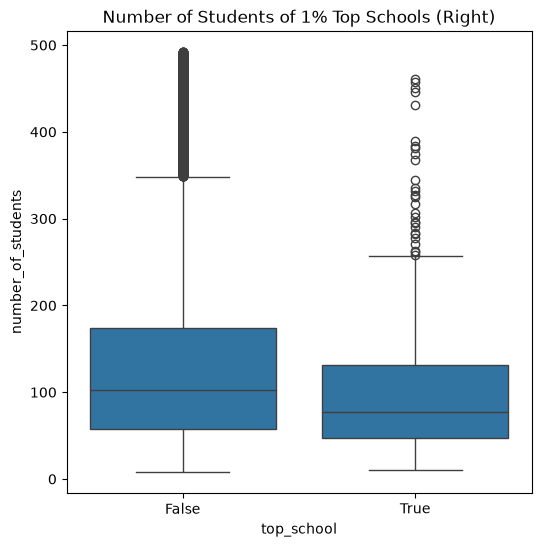

In [7]:
plt.figure(figsize=(6, 6))
sns.boxplot(x="top_school", y='number_of_students', data=plot_data)
plt.title("Number of Students of 1% Top Schools (Right)");

Text(0.5, 1.0, 'ENEM Score by Number of Students in the School')

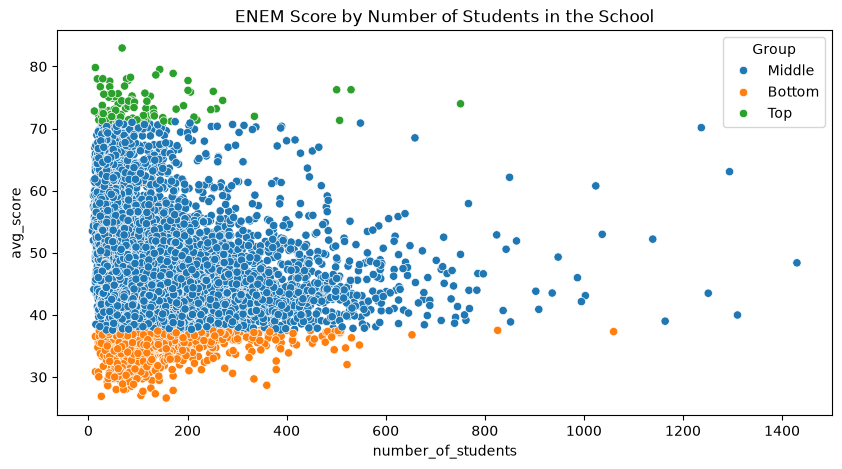

In [8]:
q_99 = np.quantile(ss_df['avg_score'], 0.99)
q_01 = np.quantile(ss_df['avg_score'], 0.1)

plot_data = (
    ss_df
    .sample(10000)
    .assign(Group=lambda d: np.select([d['avg_score'] > q_99, d['avg_score'] < q_01], ['Top', 'Bottom'], 'Middle'))
)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=plot_data, x='number_of_students', y='avg_score', hue='Group')
plt.title("ENEM Score by Number of Students in the School")

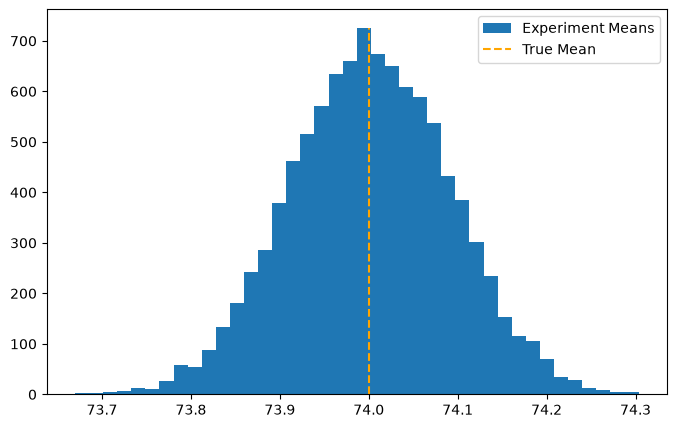

In [9]:
true_mean = 74
true_std = 2

n = 500
def run_experiment():
    return np.random.normal(true_mean, true_std, size=n)

np.random.seed()

plt.figure(figsize=(8, 5))
freq, bins, img = plt.hist([run_experiment().mean() for _ in range(10000)], bins=40, label="Experiment Means")
plt.vlines(true_mean, ymin=0, ymax=freq.max(), linestyles='--', label='True Mean', color='orange')
plt.legend();

In [10]:
np.random.seed(321)
exp_data = run_experiment()
exp_se = exp_data.std() / np.sqrt(len(exp_data))
exp_mu = exp_data.mean()
ci = ((exp_mu - 2*exp_se).item(), (exp_mu + 2*exp_se).item())

In [11]:
ci

(73.82718114045632, 74.17341543460314)

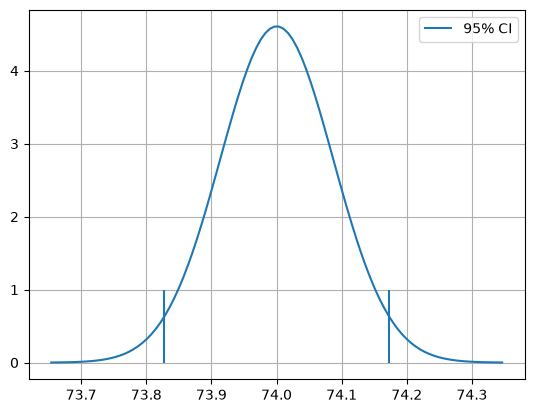

In [12]:
x = np.linspace(exp_mu - 4 * exp_se, exp_mu + 4 * exp_se, 100)
y = stats.norm.pdf(x, exp_mu, exp_se)
plt.plot(x, y)
plt.vlines(ci[0], ymin=0, ymax=1)
plt.vlines(ci[1], ymin=0, ymax=1, label="95% CI")
plt.legend()
plt.grid()
plt.show()

In [13]:
z = stats.norm.ppf(0.995)
print(z)
ci = (exp_mu - z * exp_se, exp_mu + z * exp_se)
print(ci)

2.5758293035489004
(np.float64(73.7773381773405), np.float64(74.22325839771896))


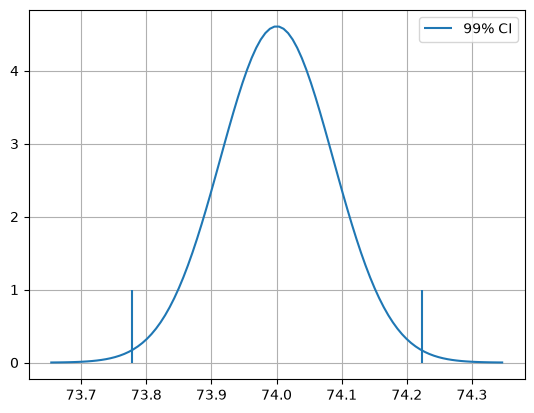

In [14]:
x = np.linspace(exp_mu - 4*exp_se, exp_mu + 4*exp_se, 100)
y = stats.norm.pdf(x, exp_mu, exp_se)
plt.plot(x, y)
plt.vlines(ci[0], ymin=0, ymax=1)
plt.vlines(ci[1], ymin=0, ymax=1, label="99% CI")
plt.grid(visible=True)
plt.legend()

In [15]:
def ci(y: pd.Series) -> float:
    return ((y.mean() - 2*(y.std()/len(y)**0.5)).item(), (y.mean() + 2*(y.std()/len(y)**0.5)).item())

In [16]:
corona_effect = pd.read_csv(project_root / 'data' / 'online_classroom.csv')
corona_effect.head()

,gender,asian,black,hawaiian,hispanic,unknown,white,format_ol,format_blended,falsexam
0,0,0.0,0.0,0.0,0.0,0.0,1.0,0,0.0,63.29997
1,1,0.0,0.0,0.0,0.0,0.0,1.0,0,0.0,79.96000
2,1,0.0,0.0,0.0,0.0,0.0,1.0,0,1.0,83.37000
3,1,0.0,0.0,0.0,0.0,0.0,1.0,0,1.0,90.01994
4,1,0.0,0.0,0.0,0.0,0.0,1.0,1,0.0,83.30000


In [17]:
online = corona_effect.loc[corona_effect['format_ol'].astype(bool) == True]['falsexam']
face_to_face = corona_effect.loc[(corona_effect['format_ol'].astype(bool) == False) & (corona_effect['format_blended'].astype(bool) == False)]['falsexam']

In [18]:
print(f"95% CI Online Learning: {ci(online)}")
print(f"95% CI Face yo Face Learning: {ci(face_to_face)}")

95% CI Online Learning: (70.56094429049804, 76.7095818797147)
95% CI Face yo Face Learning: (76.80278229206951, 80.29218687459715)


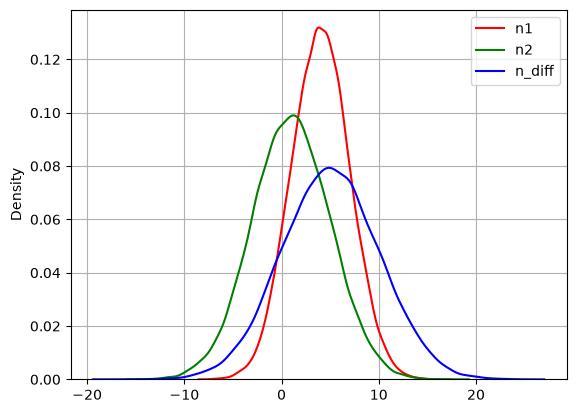

In [19]:
np.random.seed(123)
n1 = np.random.normal(4, 3, 30000)
n2 = np.random.normal(1, 4, 30000)
n_diff = n1 + n2

sns.kdeplot(data=n1, label='n1', color='red')
sns.kdeplot(data=n2, label='n2', color='green')
sns.kdeplot(data=n_diff, label='n_diff', color='blue')
plt.grid()
plt.legend();

### Summary In A Function

In [26]:
def AB_test(test: pd.Series, control: pd.Series, confidence: float, h0: int = 0):
    """This is the summary function of all the things i have learnt in this chapter.

    Args:
        test (pd.Series): Treatment Group Series
        control (pd.Series): Control Group Series
        condifence (float): Confidence for CI
        h0 (int, optional): Null hypothesis value. Defaults to 0.
    """
    
    mu_test, mu_con = test.mean(), control.mean()
    se_test, se_con = test.std()/(len(test)**0.5), control.std()/(len(control)**0.5)
    
    mu_diff = mu_test - mu_con
    se_diff = np.sqrt(test.var()/len(test) + control.var()/len(control))
    
    z_stats = (mu_diff - h0) / se_diff
    p_value = stats.norm.cdf(z_stats)
    
    def critical(se): return -se*stats.norm.ppf((1-confidence)/2)
    
    print(f"Test {confidence*100}% CI: {mu_test} +- {critical(se_test)}")
    print(f"Control {confidence*100}% CI: {mu_con} +- {critical(se_con)}")
    print(f"Test-Control {confidence*100}% CI: {mu_diff} +- {critical(se_diff)}")
    print(f"Z Statistic {z_stats}")
    print(f"P-Value {p_value}")
    
    if p_value < (1-confidence):
        print("H0 REJECTED!")
    else:
        print("H0 CAN'T BE REJECTED!!")

In [27]:
AB_test(
    test=online,
    control=face_to_face,
    confidence=0.99,
    h0=-1
)

Test 99.0% CI: 73.63526308510637 +- 3.959460219801631
Control 99.0% CI: 78.54748458333333 +- 2.2470276439031296
Test-Control 99.0% CI: -4.912221498226955 +- 4.5526320370370845
Z Statistic -2.2134920404560883
P-Value 0.013431870694630116
H0 CAN'T BE REJECTED!!
